In [3]:
import pandas as pd

data = pd.read_excel(r'employee.xlsx')

data.head()

,EEID,Full Name,Job Title,Department,Business Unit,Gender,Ethnicity,Age,Hire Date,Annual Salary,Bonus %,Country,City
0,E02387,Emily Davis,Sr. Manger,IT,Research & Development,Female,Black,55,2016-04-08,141604,0.15,United States,Seattle
1,E04105,Theodore Dinh,Technical Architect,IT,Manufacturing,Male,Asian,59,1997-11-29,99975,0.00,China,Chongqing
2,E02572,Luna Sanders,Director,Finance,Speciality Products,Female,Caucasian,50,2006-10-26,163099,0.20,United States,Chicago
3,E02832,Penelope Jordan,Computer Systems Manager,IT,Manufacturing,Female,Caucasian,26,2019-09-27,84913,0.07,United States,Chicago
4,E01639,Austin Vo,Sr. Analyst,Finance,Manufacturing,Male,Asian,55,1995-11-20,95409,0.00,United States,Phoenix


In [89]:
# descriptiv ve statistika (numeric ve categorics)
numeric_stats = data[['Age', 'Annual Salary', 'Bonus %']].describe()
print(numeric_stats)

#categorical_cols = ['Department', 'Business Unit', 'Gender', 'Ethnicity', 'Country', 'City']
#data[categorical_cols].describe()


               Age  Annual Salary      Bonus %
count  1000.000000    1000.000000  1000.000000
mean     44.382000  113217.365000     0.088660
std      11.246981   53545.985644     0.117856
min      25.000000   40063.000000     0.000000
25%      35.000000   71430.250000     0.000000
50%      45.000000   96557.000000     0.000000
75%      54.000000  150782.250000     0.150000
max      65.000000  258498.000000     0.400000


In [90]:
# categorics statistic

categorical_cols = ['Department', 'Business Unit', 'Gender', 'Ethnicity', 'Country', 'City']
data[categorical_cols].describe()

# asagida qrafiklerde en cox isci sayinin IT departmentinde(241),business unit-de Manufacturing(269) oldugunu gore bilerik

,Department,Business Unit,Gender,Ethnicity,Country,City
count,1000,1000,1000,1000,1000,1000
unique,7,4,2,4,3,13
top,IT,Manufacturing,Female,Asian,United States,Seattle
freq,241,269,518,404,643,118


In [87]:
# Departamentleri hem value counts hem de countplot ile gosterin
print(data['Department'].value_counts())



Department
IT                 241
Engineering        158
Sales              140
Human Resources    125
Finance            120
Marketing          120
Accounting          96
Name: count, dtype: int64


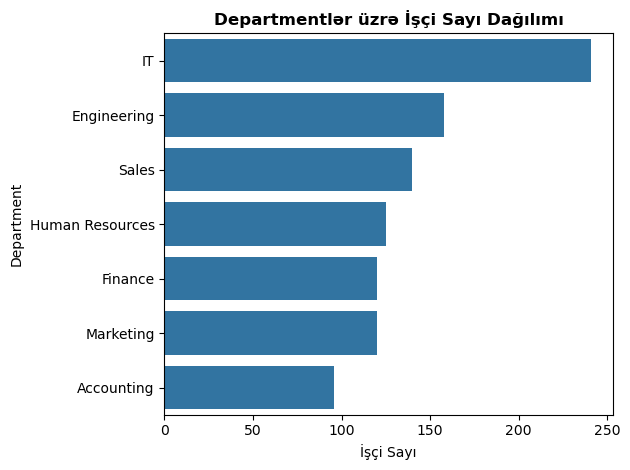

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data=data, y='Department', order=data['Department'].value_counts().index)
plt.title('Departmentlər üzrə İşçi Sayı Dağılımı', fontweight='bold')
plt.xlabel('İşçi Sayı')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

# Qrafikdən görünürr ki,ən çox isçi IT departmentindədir.

In [93]:
# Her departament uchun maashin ortalamasi, yashin minimumu ve bonuslarin maximumun gosterin 
summary_data = data.groupby('Department').agg(
    Average_Salary=('Annual Salary', 'mean'),
    Min_Age=('Age', 'min'),
    Max_Bonus=('Bonus %', 'max')
).reset_index()
print(summary_data)

# Ortalama maaş ən çox marketing üzrədir
# Min yaş 25di və max bonusu onlar aləb bu bizə gənc kadrların potensialını göstərir.

''' Əvvəlki qrafikdən İT departmentinin böyük olduğunu bilirik və orta maaşın aşağı düşməsi onu göstərir ki,yüksək sayda aşağı maaşlı kadr var.Bu da ümumi ortalamanı aşağı edir.

        Department  Average_Salary  Min_Age  Max_Bonus
0       Accounting   123146.947917       25       0.40
1      Engineering   109035.208861       25       0.40
2          Finance   122802.891667       25       0.39
3  Human Resources   118058.440000       25       0.39
4               IT    97790.452282       25       0.39
5        Marketing   129663.033333       25       0.40
6            Sales   111049.857143       25       0.38


In [22]:
# Olkeler uzre maashin maksimumu, yashin ortalamasi ve bonuslarin ortalamasin gosterin 
summary_data = data.groupby('Country').agg(
    Max_Salary=('Annual Salary', 'max'),
    Average_Age=('Age', 'mean'),
    Average_Bonus=('Bonus %', 'mean')
).reset_index()
print(summary_data)



         Country  Max_Salary  Average_Age  Average_Bonus
0         Brazil      258426    43.654676       0.086763
1          China      257194    45.389908       0.084954
2  United States      258498    44.197512       0.090327


Ən yüksək orta maaş olan şəhər: Shanghai - 119972.01923076923


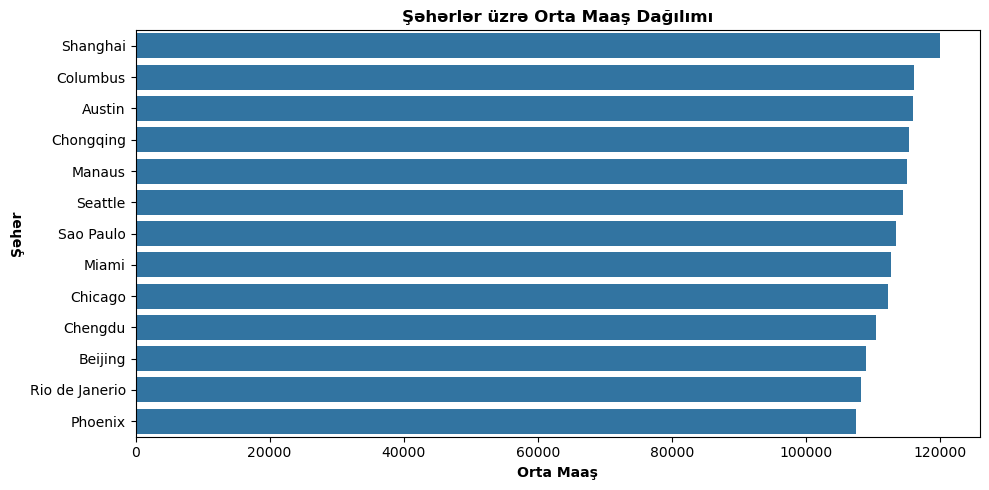

In [67]:
# barplot ile sheherler uchun orta maashi plot edin, en yuksek orta maash hansi sheherdedir qeyd edin.
city_salary = data.groupby('City')['Annual Salary'].mean().reset_index()
city_salary = city_salary.sort_values(by='Annual Salary', ascending=False)
top_city = city_salary.iloc[0]['City']
top_salary = city_salary.iloc[0]['Annual Salary']
print(f"Ən yüksək orta maaş olan şəhər: {top_city} - {top_salary}")

plt.figure(figsize=(10, 5))
sns.barplot(
    data=city_salary, 
    x='Annual Salary', 
    y='City'
)
plt.title('Şəhərlər üzrə Orta Maaş Dağılımı', fontweight='bold')
plt.xlabel('Orta Maaş',fontweight='bold')
plt.ylabel('Şəhər',fontweight='bold')
plt.tight_layout()
plt.show()

# Ən yüksək orta illik maaş Shanghai ofisimizdə qeydə alınmışdır.
# Qrafikə baxsaq coğrafi ayrı-seçkilik etmədən istedadları bərabər qiymətləndirdiyini görə bilərik.

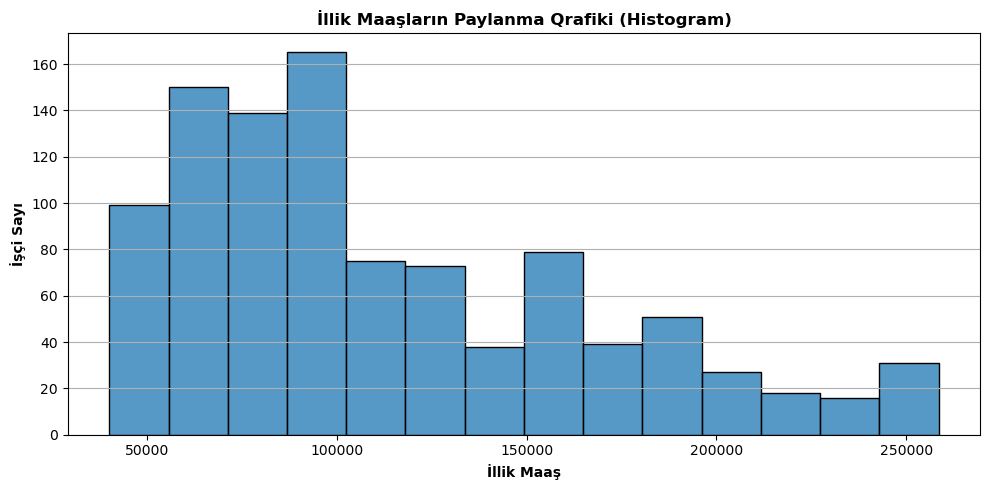

In [66]:
# Annual Salary-nin histogram/distribution qrafiki
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x='Annual Salary')
plt.title('İllik Maaşların Paylanma Qrafiki (Histogram)', fontweight='bold')
plt.xlabel('İllik Maaş',fontweight='bold')
plt.ylabel('İşçi Sayı',fontweight='bold')
plt.grid(axis='y', linestyle='-')
plt.tight_layout()
plt.show()


# Kadr kapitalının böyük hissəsi 50,000 - 100,000 orta gəlir qrupunda yerləşir


   Gender  Annual Salary
0  Female  112314.179537
1    Male  114188.008299


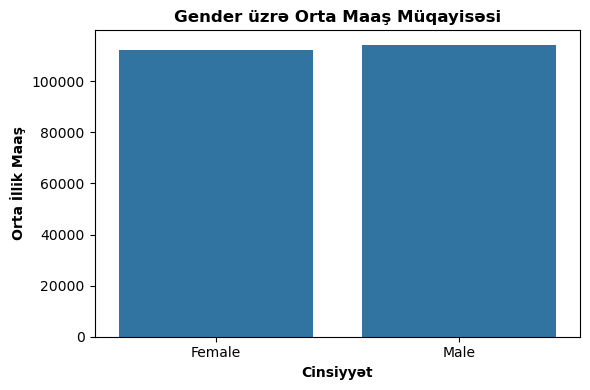

In [65]:
# Gender üzrə orta maaş müqayisəsi (groupby + barplot)
gender_salary = data.groupby('Gender')['Annual Salary'].mean().reset_index()
print(gender_salary)
plt.figure(figsize=(6, 4))
sns.barplot(data=gender_salary, x='Gender', y='Annual Salary')
plt.title('Gender üzrə Orta Maaş Müqayisəsi',fontweight='bold')
plt.xlabel('Cinsiyyət',fontweight='bold')
plt.ylabel('Orta İllik Maaş',fontweight='bold')
plt.tight_layout()
plt.show()


# Qrafikdə qadın və kişilərin orta maaş sütunları bir-birinə çox yaxındır, bu, şirkətdə bərabərlik prinsipi qorunurduğunu göstərir. Eyni vəzifədə və ya bənzər statusda olan işçilər cinsindən asılı olmayaraq ədalətli maaş alırlar.


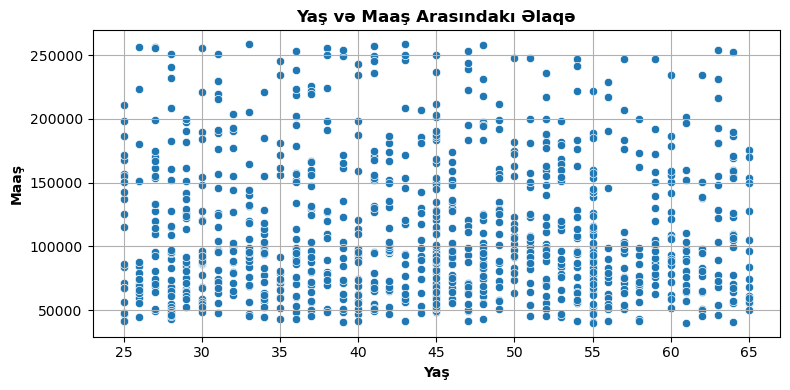

In [64]:
# Salary ilə Age arasında əlaqə (scatterplot)
plt.figure(figsize=(8, 4))
# 3. Scatterplot qururuq
sns.scatterplot(data=data, x='Age', y='Annual Salary')

# Qrafik başlıqları və tənzimləmələr
plt.title('Yaş və Maaş Arasındakı Əlaqə', fontweight='bold')
plt.xlabel('Yaş',fontweight='bold')
plt.ylabel('Maaş',fontweight='bold')
plt.grid(True, linestyle='-')
plt.tight_layout()
plt.show()

# Gənc yaşda yüksək maaş alan və 60 üstü olan işçilərdən aşağı maaş alanlar var,bu şirkətin işçiyə yaşına görə yox, onun şirkətə qazandırdığı dəyərə, vəzifəsinə görə maaş verdiyini göstərir



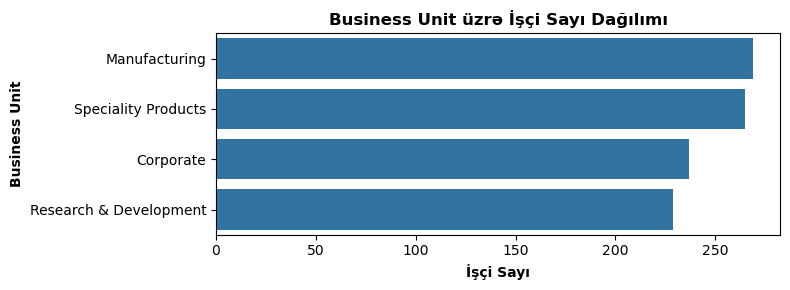

In [71]:
# Business Unit üzrə işçi sayı (countplot)
plt.figure(figsize=(8, 3))
sns.countplot(data=data, y='Business Unit', order=data['Business Unit'].value_counts().index)
plt.title('Business Unit üzrə İşçi Sayı Dağılımı', fontweight='bold')
plt.xlabel('İşçi Sayı',fontweight='bold')
plt.ylabel('Business Unit',fontweight='bold')
plt.tight_layout()
plt.show()


# Istehsalat və xüsusi məhsul üzrə işçi sayının çox olması şirkətin gəlir mexanizmi bu iki sahənin üzərində qurulduğunu göstərir



In [80]:
# Country/City üzrə ən çox işçi olan yerlər 
location_counts = data.groupby(['Country', 'City']).size().reset_index(name='Employee_Count')
location_counts['Location'] = location_counts['Country'] + ' (' + location_counts['City'] + ')'
location_counts = location_counts.sort_values(by='Employee_Count', ascending=False)
top_locations=location_counts.head(10)
print(top_locations)

          Country       City  Employee_Count                  Location
12  United States    Seattle             118   United States (Seattle)
9   United States   Columbus             113  United States (Columbus)
10  United States      Miami             112     United States (Miami)
11  United States    Phoenix             109   United States (Phoenix)
7   United States     Austin              99    United States (Austin)
8   United States    Chicago              92   United States (Chicago)
5           China  Chongqing              65         China (Chongqing)
3           China    Beijing              55           China (Beijing)
2          Brazil  Sao Paulo              53        Brazil (Sao Paulo)
6           China   Shanghai              52          China (Shanghai)


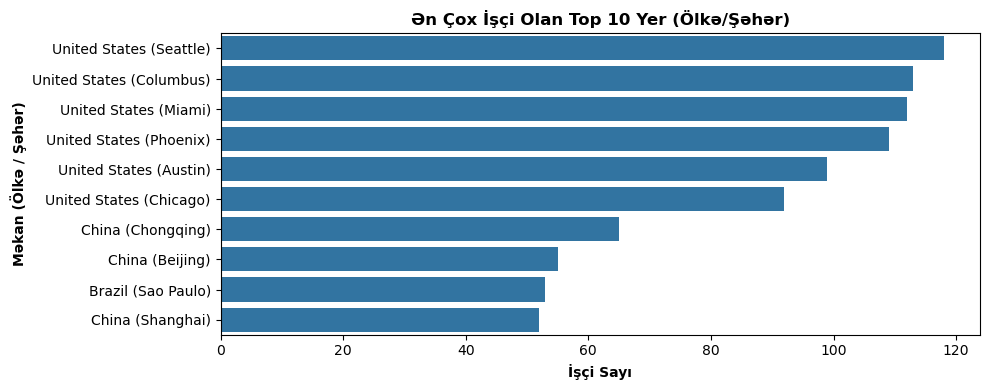

In [85]:
plt.figure(figsize=(10, 4))
sns.barplot(
    data= top_locations, 
    x='Employee_Count', 
    y='Location'
)
plt.title('Ən Çox İşçi Olan Top 10 Yer (Ölkə/Şəhər)',fontweight='bold')
plt.xlabel('İşçi Sayı', fontweight='bold')
plt.ylabel('Məkan (Ölkə / Şəhər)',fontweight='bold')
plt.tight_layout()
plt.show()


# Ən çox işçi sayı ABŞ-dadır.Şirkətin əsas əməliyyat bazasını ABŞ təşkil edir.